# Time Series Analysis — US Accidents Dataset

**This notebook covers Axis 3 — "How does the number of accidents evolve over time?"**

It uses `monthly_counts_full.csv`, produced by `01_EDA.ipynb` from the **full** dataset (exact monthly counts, not counts on a sample).

Mechanisms used in this notebook:
- Selection of the reliable analysis window (data coverage check)
- Seasonal decomposition (trend / seasonality / residual)
- Stationarity test (ADF) and differencing
- ACF / PACF
- ARIMA model selected by AIC, with a 6-month forecast
- Backtest on the last 6 months
- Ljung-Box test on the residuals

---


## 0. Configuration and imports

In [ ]:
from pathlib import Path
import itertools
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)

DATA_DIR = Path("D:/Accidents_USA/Dataset")   
MONTHLY_PATH = DATA_DIR / "D:\\US\\Dataset\\monthly_counts_full.csv"   


## 1. Loading the monthly counts

In [2]:
monthly_counts = (
    pd.read_csv(MONTHLY_PATH, parse_dates=['month'], index_col='month')['accident_count']
      .asfreq('MS')
)
print(f"{len(monthly_counts)} months: {monthly_counts.index.min().date()} -> {monthly_counts.index.max().date()}")
print(f"Total accidents counted: {monthly_counts.sum():,}")


80 months: 2016-02-01 -> 2022-09-01
Total accidents counted: 1,410,124


---
## 2. Selecting the reliable analysis window



In [ ]:
series_trimmed = monthly_counts.iloc[1:-1]

# 2) longest continuous run of months with at least MIN_COUNT accidents
MIN_COUNT = 1
covered = series_trimmed >= MIN_COUNT
run_id = (covered != covered.shift()).cumsum()

runs = (
    pd.DataFrame({'covered': covered, 'run_id': run_id, 'month': series_trimmed.index})
      .query('covered')
      .groupby('run_id')['month']
      .agg(['min', 'max', 'count'])
      .sort_values('count', ascending=False)
)
display(runs.head())

best_run = runs.iloc[0]
window_start, window_end = best_run['min'], best_run['max']
series = series_trimmed.loc[window_start:window_end]

print(f"Selected window: {window_start.date()} -> {window_end.date()} ({len(series)} months)")
if len(series) < 36:
    print("WARNING: fewer than 36 months. Seasonal decomposition and ARIMA will be fragile; interpret with caution.")


,min,max,count
run_id,,,
3,2020-07-01,2022-08-01,26
1,2016-03-01,2017-07-01,17


Selected window: 2020-07-01 -> 2022-08-01 (26 months)


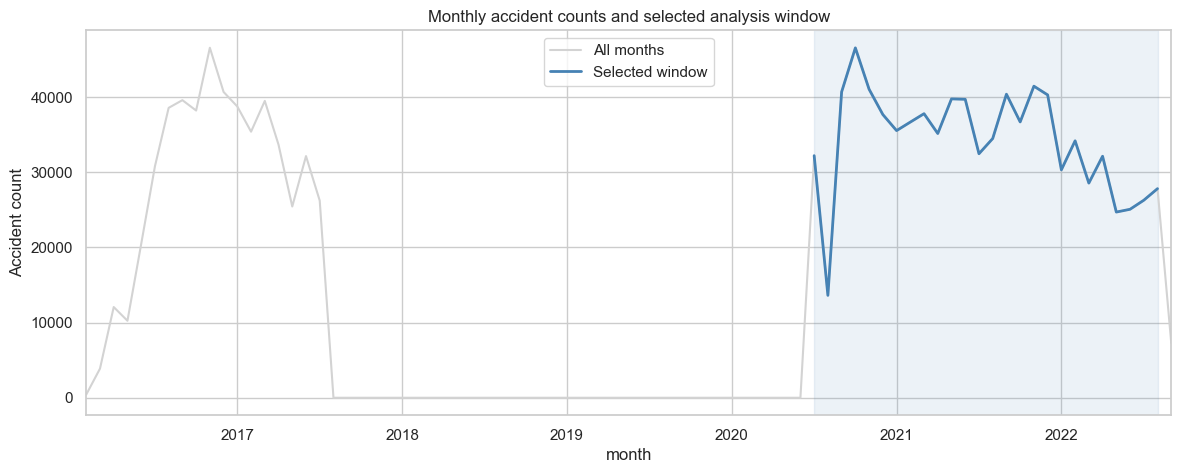

In [4]:
plt.figure(figsize=(14, 5))
monthly_counts.plot(label='All months', color='lightgray')
series.plot(label='Selected window', color='steelblue', linewidth=2)
plt.axvspan(window_start, window_end, alpha=0.1, color='steelblue')
plt.title("Monthly accident counts and selected analysis window")
plt.ylabel("Accident count")
plt.legend()
plt.show()


---
## 3. Seasonal decomposition (trend / seasonality / residual)

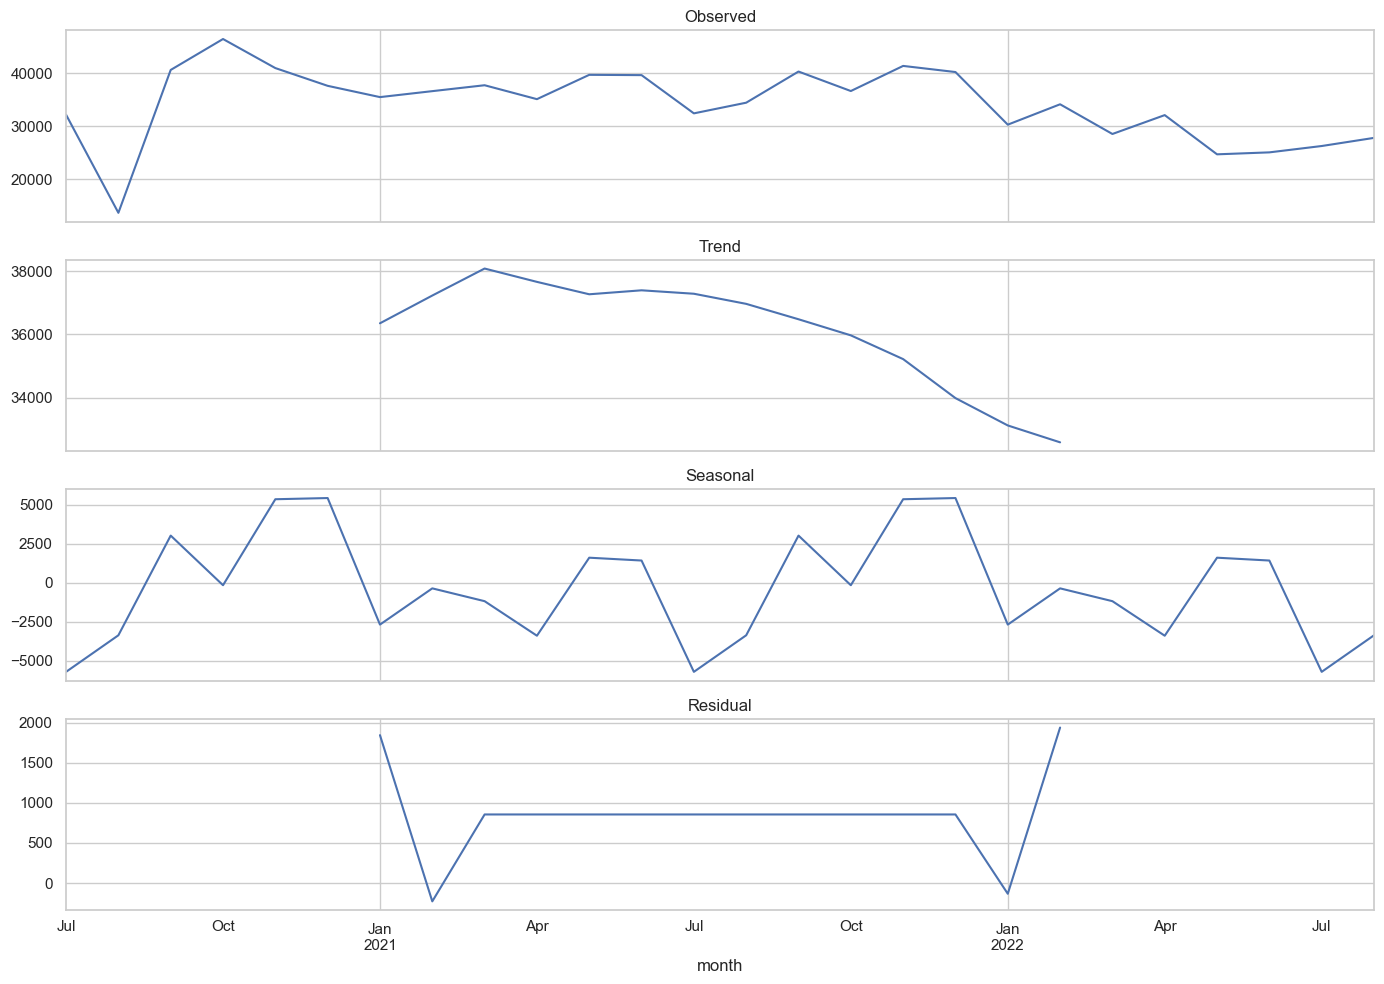

In [5]:
decomposition = seasonal_decompose(series, model='additive', period=12)

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
decomposition.observed.plot(ax=axes[0], title='Observed')
decomposition.trend.plot(ax=axes[1], title='Trend')
decomposition.seasonal.plot(ax=axes[2], title='Seasonal')
decomposition.resid.plot(ax=axes[3], title='Residual')
plt.tight_layout()
plt.show()


In [6]:
# Average seasonal effect per calendar month
seasonal_by_month = decomposition.seasonal.groupby(decomposition.seasonal.index.month).mean().round(0)
seasonal_by_month.index.name = 'month'
seasonal_by_month


month
1    -2679.0
2     -358.0
3    -1179.0
4    -3391.0
5     1606.0
6     1425.0
7    -5705.0
8    -3363.0
9     3022.0
10    -156.0
11    5350.0
12    5427.0
Name: seasonal, dtype: float64

---
## 4. Stationarity test — Augmented Dickey-Fuller (ADF)

ADF on the original series: statistic = -3.1958, p-value = 0.0202
=> differencing order used for ARIMA: d = 0


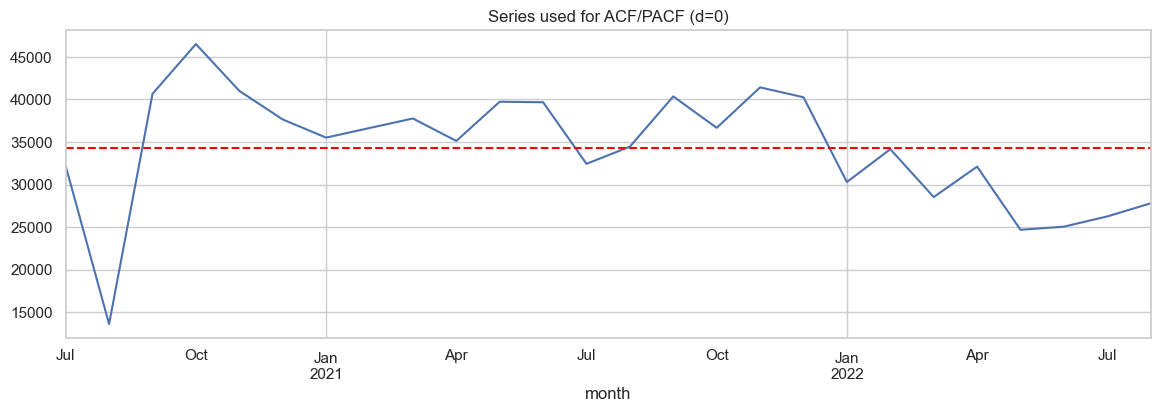

In [7]:
adf_stat, adf_p, *_ = adfuller(series)
print(f"ADF on the original series: statistic = {adf_stat:.4f}, p-value = {adf_p:.4f}")

d = 0 if adf_p < 0.05 else 1

if d == 1:
    series_diff = series.diff().dropna()
    adf_stat_d, adf_p_d, *_ = adfuller(series_diff)
    print(f"ADF after 1 differencing:   statistic = {adf_stat_d:.4f}, p-value = {adf_p_d:.4f}")
else:
    series_diff = series

print(f"=> differencing order used for ARIMA: d = {d}")

series_diff.plot(title=f"Series used for ACF/PACF (d={d})", figsize=(14, 4))
plt.axhline(series_diff.mean(), color='red', linestyle='--')
plt.show()


---
## 5. ACF / PACF

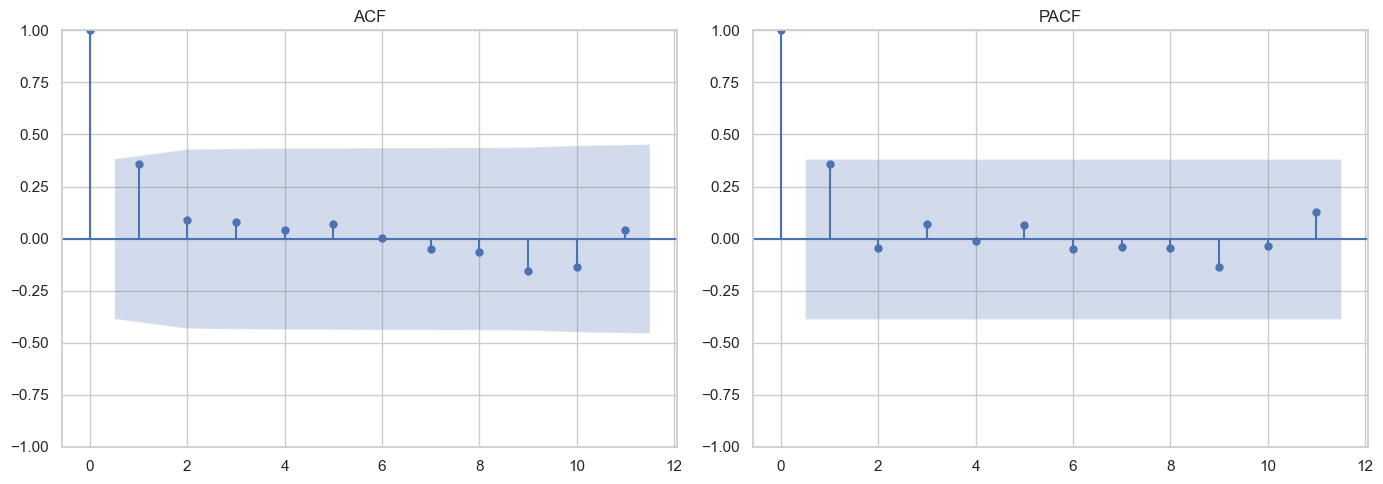

In [8]:
max_lags = max(4, min(24, len(series_diff) // 2 - 2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_acf(series_diff, ax=axes[0], lags=max_lags)
plot_pacf(series_diff, ax=axes[1], lags=max_lags)
axes[0].set_title("ACF")
axes[1].set_title("PACF")
plt.tight_layout()
plt.show()


---
## 6. ARIMA — order selected by AIC, then forecast

In [9]:
results = []
for p, q in itertools.product(range(0, 4), range(0, 4)):
    try:
        fit = ARIMA(series, order=(p, d, q)).fit()
        results.append((p, d, q, fit.aic))
    except Exception:
        continue

grid = pd.DataFrame(results, columns=['p', 'd', 'q', 'AIC']).sort_values('AIC').reset_index(drop=True)
display(grid.head(5))

best_order = tuple(int(x) for x in grid.loc[0, ['p', 'd', 'q']])
print(f"Best order by AIC: ARIMA{best_order}")


,p,d,q,AIC
0,0,0,1,535.593720
1,1,0,0,535.685112
2,0,0,0,537.224363
3,0,0,2,537.591181
4,1,0,1,537.670114


Best order by AIC: ARIMA(0, 0, 1)


In [10]:
arima_fit = ARIMA(series, order=best_order).fit()
print(arima_fit.summary())


                               SARIMAX Results                                
Dep. Variable:         accident_count   No. Observations:                   26
Model:                 ARIMA(0, 0, 1)   Log Likelihood                -264.797
Date:                Sun, 25 Oct 2026   AIC                            535.594
Time:                        18:00:38   BIC                            539.368
Sample:                    07-01-2020   HQIC                           536.681
                         - 08-01-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       3.426e+04   1924.136     17.807      0.000    3.05e+04     3.8e+04
ma.L1          0.3940      0.147      2.689      0.007       0.107       0.681
sigma2      4.082e+07      0.209   1.95e+08      0.0

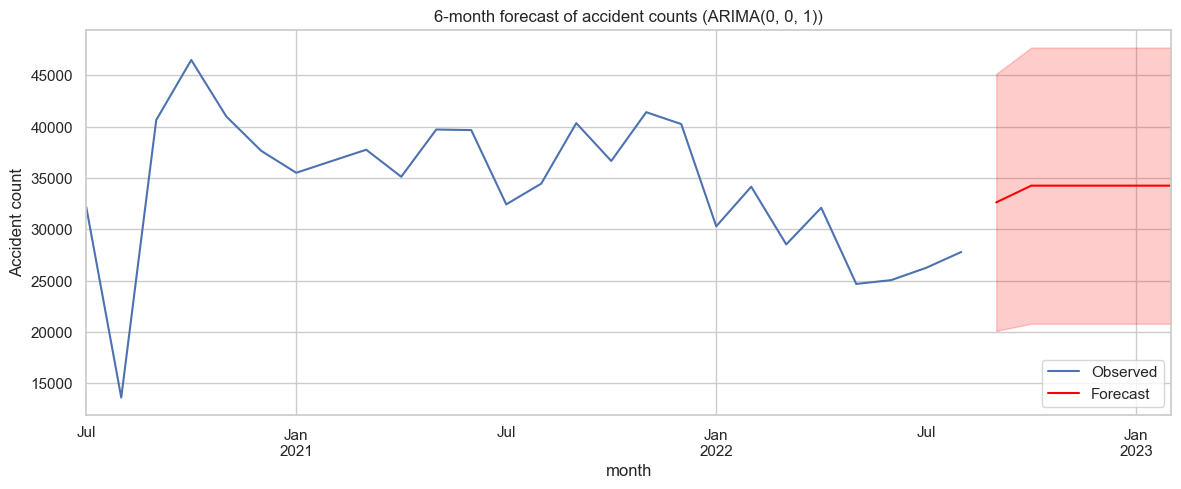

2022-09-01    32630.0
2022-10-01    34263.0
2022-11-01    34263.0
2022-12-01    34263.0
2023-01-01    34263.0
2023-02-01    34263.0
Freq: MS, Name: predicted_mean, dtype: float64

In [11]:
forecast_steps = 6
forecast = arima_fit.get_forecast(steps=forecast_steps)
forecast_mean = forecast.predicted_mean
forecast_ci = forecast.conf_int()

plt.figure(figsize=(14, 5))
series.plot(label='Observed')
forecast_mean.plot(label='Forecast', color='red')
plt.fill_between(forecast_ci.index, forecast_ci.iloc[:, 0], forecast_ci.iloc[:, 1], color='red', alpha=0.2)
plt.title(f"{forecast_steps}-month forecast of accident counts (ARIMA{best_order})")
plt.ylabel("Accident count")
plt.legend()
plt.show()

forecast_mean.round(0)


### 6.1 Backtest — how good is the model on data it has not seen?



Backtest on the last 6 months -> MAE = 8,911 accidents/month, MAPE = 33.6%


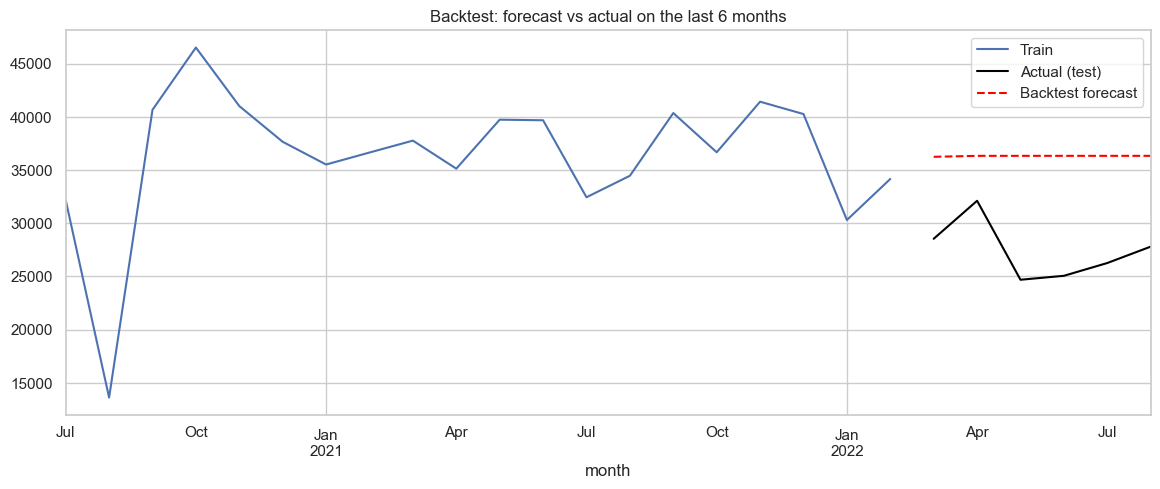

In [12]:
H = 6
train, test = series.iloc[:-H], series.iloc[-H:]

bt_fit = ARIMA(train, order=best_order).fit()
bt_pred = bt_fit.forecast(steps=H)

mae = np.mean(np.abs(test.values - bt_pred.values))
mape = np.mean(np.abs((test.values - bt_pred.values) / test.values)) * 100
print(f"Backtest on the last {H} months -> MAE = {mae:,.0f} accidents/month, MAPE = {mape:.1f}%")

plt.figure(figsize=(14, 5))
train.plot(label='Train')
test.plot(label='Actual (test)', color='black')
bt_pred.plot(label='Backtest forecast', color='red', linestyle='--')
plt.title("Backtest: forecast vs actual on the last 6 months")
plt.legend()
plt.show()


---
## 7. Ljung-Box test — residual diagnostics

,lb_stat,lb_pvalue
8,0.559661,0.999796


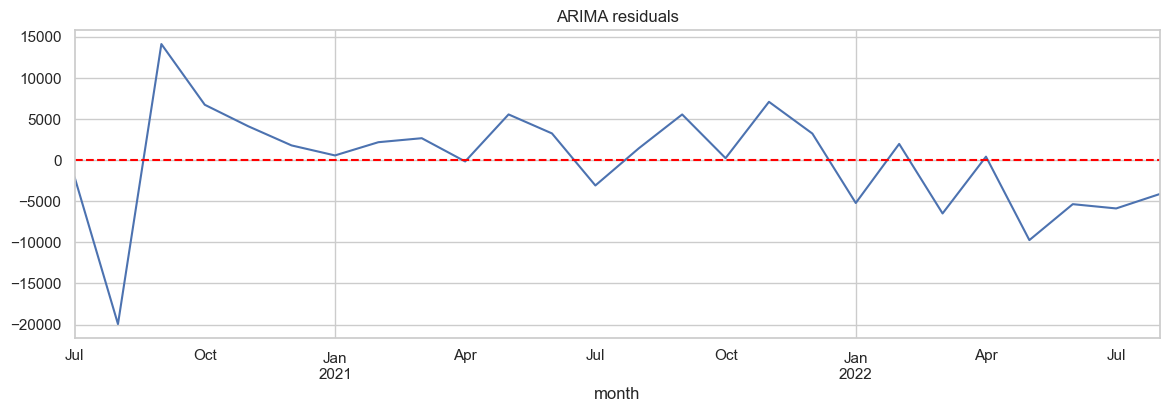

In [ ]:
resid = arima_fit.resid.iloc[d:]   

lb_lags = max(2, min(10, len(resid) // 3))
lb = acorr_ljungbox(resid, lags=[lb_lags], return_df=True)
display(lb)

fig, ax = plt.subplots(figsize=(14, 4))
resid.plot(ax=ax)
ax.axhline(0, color='red', linestyle='--')
ax.set_title("ARIMA residuals")
plt.show()
